
# Decision Tree Classifier (80/20 split) — CUB-200-2011 Tabular Attributes

This is the **80/20 split** version of [`decisionTree.ipynb`](decisionTree.ipynb). The code and protocol are the same, but it trains on the stratified 80/20 split (`is_train_80`, built in `dataPrep.ipynb` §8) instead of the official, roughly 50/50 split:

| | Official (`is_train`) | 80/20 (`is_train_80`) |
|---|---|---|
| Train | 5,994 (29–30 per species) | 9,430 (33–48 per species) |
| Test | 5,794 (11–30 per species) | 2,358 (8–12 per species) |

**Input:** the feature files written by [`dataPrep.ipynb`](dataPrep.ipynb) (run that first).
**Protocol:** all tuning and variant selection use stratified 5-fold CV on the **training portion only**. There is no separate validation set. The test set is used once, at the end. Everything is re-tuned from scratch on this split; nothing is carried over from the official-split notebook.

**Differences from the official-split notebook:**
- `class_weight` is added to the grid, because the 80/20 training classes are uneven (33–48 images).
- A new §9 compares the result with the official split and separates the effect of *more training data* from the effect of *a different test set*.

| Step | Section |
|---|---|
| Baseline (default tree) | 2 |
| Validation curves for each hyperparameter | 3 |
| Grid search | 4 |
| Feature variant comparison (A / B / C) | 5 |
| Final test evaluation | 6 |
| Error analysis | 7 |
| Interpretation (tree, rules, feature importances) | 8 |
| Comparison with the official split | 9 |


## 1. Setup

Evaluation choices are the same as in the official-split notebook:
- **Stratified 5-fold CV on the training set** is used for all tuning. Stratification keeps each species' proportion the same in every fold, giving about 7–10 images per species in each validation fold (vs about 6 on the official split). 5 folds balances the variance of the estimate against runtime. With only about 30 images per class, a separate fixed validation split would be too small to be reliable.
- **Accuracy is the selection metric.** Accuracy is kept as the selection metric for consistency with the official-split notebook. The training classes are now mildly uneven (33–48), so macro-F1 is reported next to it to check that the chosen model doesn't favour the larger species.
- **Top-5 accuracy** is reported at the end as a secondary metric, to show whether the correct species is at least among the model's top guesses.
- **`RANDOM_STATE = 42`** fixes the folds and the tree's tie-breaking, so every number in this notebook is reproducible.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, validation_curve
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, confusion_matrix

RANDOM_STATE = 42
SPLIT = 'is_train_80'  # stratified 80/20 split; decisionTree.ipynb uses the official 'is_train'
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train', 'is_train_80']  # never used as features

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}

def load_variant(name):
    """Return X_train, y_train, X_test, y_test for feature variant A, B or C."""
    path = DATA / f'cub_features_{name}.csv'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/dataPrep.ipynb first')
    df = pd.read_csv(path)
    features = [c for c in df.columns if c not in META_COLS]
    train, test = df[df[SPLIT] == 1], df[df[SPLIT] == 0]
    return train[features], train.class_id, test[features], test.class_id

X_train, y_train, X_test, y_test = load_variant('A')
class_names = pd.read_csv(DATA / 'cub_features_A.csv', usecols=['class_id', 'class_name']) \
                .drop_duplicates().set_index('class_id').class_name.sort_index()

print('train', X_train.shape, '| test', X_test.shape, '| classes', y_train.nunique())
print(f'chance accuracy: {1 / y_train.nunique():.3%}')

train (9430, 312) | test (2358, 312) | classes 200
chance accuracy: 0.500%


## 2. Baseline: default decision tree

The default tree is the reference point. Any tuning has to beat it on CV to be worth keeping. An unrestricted tree grows until every leaf is pure, so it should memorise the training set. The gap between training accuracy and CV accuracy measures how much it overfits.

In [2]:
baseline = DecisionTreeClassifier(random_state=RANDOM_STATE)
cv_base = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True)

baseline.fit(X_train, y_train)
print(f'depth: {baseline.get_depth()}, leaves: {baseline.get_n_leaves()}')
print(f"train accuracy (CV folds): {cv_base['train_accuracy'].mean():.3f}")
print(f"CV accuracy:               {cv_base['test_accuracy'].mean():.3f} ± {cv_base['test_accuracy'].std():.3f}")
print(f"CV macro-F1:               {cv_base['test_f1_macro'].mean():.3f} ± {cv_base['test_f1_macro'].std():.3f}")

depth: 53, leaves: 5223
train accuracy (CV folds): 0.999
CV accuracy:               0.268 ± 0.010
CV macro-F1:               0.264 ± 0.010


## 3. Validation curves

**Why:** searching a grid blind wastes runtime and can miss the useful range. We first vary one hyperparameter at a time (the others at their defaults), for both split criteria. This shows where performance changes, so the grid in §4 can focus there.

- `max_depth`, `min_samples_leaf` and `min_samples_split` are the standard pre-pruning controls (they stop the tree growing early). `ccp_alpha` is post-pruning (grow fully, then cut back weak branches). Testing both families shows whether *any* kind of regularisation helps.
- The `ccp_alpha` values are taken from quantiles of the baseline tree's own **pruning path**, rather than an arbitrary grid. This guarantees that each value actually removes a different number of branches.
- Each panel shows both train (dashed) and CV (solid) accuracy. The gap between them is the overfitting.

**Reading the curves** (the same picture as on the official split, a couple of points higher overall):
- CV accuracy rises with `max_depth` up to about 25–30 and then plateaus. Shallower trees underfit. With more training images the tree grows slightly deeper (the baseline has depth 53 vs 46).
- `min_samples_leaf`, `min_samples_split` and `ccp_alpha` cut training accuracy sharply but leave CV accuracy flat, only falling off at the largest values.
- Gini is consistently about 4 points above entropy.

So the grid ranges used on the official split still cover the useful region and are kept unchanged.

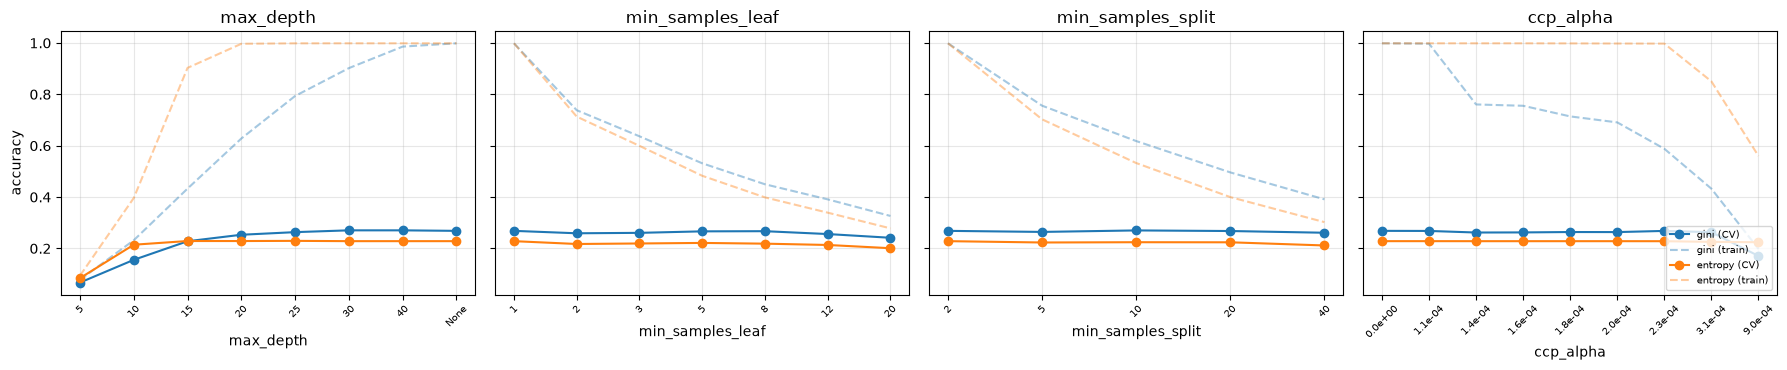

In [3]:
ccp_path = baseline.cost_complexity_pruning_path(X_train, y_train)
alpha_grid = np.unique(np.quantile(ccp_path.ccp_alphas, np.linspace(0, 0.98, 12)).round(6))

curves = {
    'max_depth': [5, 10, 15, 20, 25, 30, 40, None],
    'min_samples_leaf': [1, 2, 3, 5, 8, 12, 20],
    'min_samples_split': [2, 5, 10, 20, 40],
    'ccp_alpha': list(alpha_grid),
}

fig, axes = plt.subplots(1, len(curves), figsize=(18, 3.8), sharey=True)
for ax, (param, values) in zip(axes, curves.items()):
    for criterion, colour in [('gini', 'tab:blue'), ('entropy', 'tab:orange')]:
        tr, va = validation_curve(DecisionTreeClassifier(criterion=criterion, random_state=RANDOM_STATE),
                                  X_train, y_train, param_name=param, param_range=values,
                                  cv=CV, scoring='accuracy', n_jobs=-1)
        x = np.arange(len(values))
        ax.plot(x, va.mean(1), 'o-', color=colour, label=f'{criterion} (CV)')
        ax.plot(x, tr.mean(1), '--', color=colour, alpha=0.4, label=f'{criterion} (train)')
    ax.set_xticks(x, [str(v) if not isinstance(v, float) else f'{v:.1e}' for v in values],
                  rotation=45, fontsize=7)
    ax.set(title=param, xlabel=param)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('accuracy')
axes[-1].legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

## 4. Grid search (variant A)

**How the ranges were chosen from §3** (the same ranges as on the official split, which the curves above support):
- `max_depth`: 15–30 and `None`. Below 15 the tree clearly underfits, so smaller values are not worth testing.
- `min_samples_leaf`: 1–5 and `min_samples_split`: 2–10. Larger values only lowered CV accuracy.
- `ccp_alpha`: 0–1e-3. Above about 1e-3 the pruning removes most of the tree.
- Both criteria are kept, so the gini-vs-entropy choice is decided by CV rather than by the curves alone.
- `class_weight` ∈ {`None`, `'balanced'`} (new for this split). `'balanced'` weights each species inversely to its training count, so species with 48 images don't outvote species with 33. Testing both lets CV decide whether the mild imbalance matters.

That gives 2 × 4 × 4 × 3 × 5 × 2 = 960 combinations × 5 folds. The model is selected on mean CV accuracy and refit on the whole training set.

**Ties:** the top configurations are all within about 0.2 points of each other, well inside the fold standard deviation (about 1 point). The selected setting (`min_samples_leaf=2`, `min_samples_split=10`) is the highest mean, but it isn't meaningfully better than the unrestricted tree. `ccp_alpha = 0` and `1e-4` again give identical trees.

In [4]:
PARAM_GRID = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [15, 20, 30, None],
    'min_samples_leaf': [1, 2, 3, 5],
    'min_samples_split': [2, 5, 10],
    'ccp_alpha': [0.0, 1e-4, 3e-4, 6e-4, 1e-3],
    'class_weight': [None, 'balanced'],
}

def grid_search(X, y):
    gs = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), PARAM_GRID,
                      cv=CV, scoring=SCORING, refit='accuracy', n_jobs=-1)
    return gs.fit(X, y)

gs_A = grid_search(X_train, y_train)
n_combos = len(gs_A.cv_results_['params'])
print(f'{n_combos} combinations x {CV.get_n_splits()} folds')
print('best params:', gs_A.best_params_)
print(f'best CV accuracy: {gs_A.best_score_:.3f}')

def top_results(gs, n=10):
    res = pd.DataFrame(gs.cv_results_)
    cols = ['param_' + p for p in PARAM_GRID] + ['mean_test_accuracy', 'std_test_accuracy', 'mean_test_f1_macro']
    return res.sort_values('rank_test_accuracy')[cols].head(n).round(4)

top_results(gs_A)

/Users/ryangoh/f20dl-coursework-1/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


960 combinations x 5 folds
best params: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10}
best CV accuracy: 0.271


,param_criterion,param_max_depth,param_min_samples_leaf,param_min_samples_split,param_ccp_alpha,param_class_weight,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro
41,gini,None,2,10,0.0000,NaN,0.2713,0.0100,0.2646
233,gini,None,2,10,0.0001,NaN,0.2709,0.0104,0.2644
24,gini,30,1,2,0.0000,NaN,0.2704,0.0103,0.2673
218,gini,30,1,10,0.0001,NaN,0.2703,0.0091,0.2676
26,gini,30,1,10,0.0000,NaN,0.2703,0.0091,0.2675
230,gini,None,1,10,0.0001,NaN,0.2702,0.0081,0.2653
332,gini,None,3,10,0.0001,balanced,0.2702,0.0104,0.2653
216,gini,30,1,2,0.0001,NaN,0.2701,0.0100,0.2670
38,gini,None,1,10,0.0000,NaN,0.2701,0.0082,0.2652
137,gini,None,2,10,0.0000,balanced,0.2699,0.0095,0.2657


## 5. Compare feature variants

We run the same grid search on each "not visible" encoding (see `tabularDataAnalysis.md` §3.3):
- **A**: raw 0/1
- **B**: −1 / 0 / 1
- **C**: A + 28 per-body-part not-visible flags

Each variant gets its **own full grid search**, so no encoding is disadvantaged by hyperparameters tuned for another. The variant with the highest CV accuracy is selected, never using the test set.

**Interpreting the result:** a difference only matters if it is larger than the fold-to-fold standard deviation (`cv_acc_std`). If the variants are within that noise, they are effectively tied, and the simplest (A) is the sensible choice.

In [5]:
searches = {'A': gs_A}
for name in ['B', 'C']:
    Xv, yv, _, _ = load_variant(name)
    searches[name] = grid_search(Xv, yv)

def best_row(gs):
    i = gs.best_index_
    r = gs.cv_results_
    return {'cv_accuracy': r['mean_test_accuracy'][i], 'cv_acc_std': r['std_test_accuracy'][i],
            'cv_f1_macro': r['mean_test_f1_macro'][i], **gs.best_params_}

variant_table = pd.DataFrame({k: best_row(v) for k, v in searches.items()}).T
variant_table

/Users/ryangoh/f20dl-coursework-1/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/Users/ryangoh/f20dl-coursework-1/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,cv_accuracy,cv_acc_std,cv_f1_macro,ccp_alpha,class_weight,criterion,max_depth,min_samples_leaf,min_samples_split
A,0.271262,0.009951,0.264561,0.0,None,gini,None,2,10
B,0.271898,0.008663,0.267433,0.0,balanced,gini,None,2,10
C,0.271792,0.008191,0.265811,0.0001,None,gini,None,1,10


In [6]:
BEST_VARIANT = variant_table.cv_accuracy.astype(float).idxmax()
best_gs = searches[BEST_VARIANT]
print(f'selected variant: {BEST_VARIANT}  params: {best_gs.best_params_}')

selected variant: B  params: {'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10}


## 6. Final evaluation on the test set

`GridSearchCV` has already refit the best configuration on the full training set. This is the only time the test set is used. Evaluating once, after every decision is fixed, means the test score is an honest estimate of performance on unseen images. The default tree's test accuracy is printed alongside, to show how much tuning gained (or didn't).

In [7]:
X_train, y_train, X_test, y_test = load_variant(BEST_VARIANT)
model = best_gs.best_estimator_

y_pred = model.predict(X_test)
proba = model.predict_proba(X_test)

results = {
    'variant': BEST_VARIANT,
    'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
    'cv_accuracy': best_gs.best_score_,
    'test_accuracy': accuracy_score(y_test, y_pred),
    'test_f1_macro': f1_score(y_test, y_pred, average='macro'),
    'test_top5_accuracy': top_k_accuracy_score(y_test, proba, k=5, labels=model.classes_),
    'depth': model.get_depth(),
    'leaves': model.get_n_leaves(),
}
baseline_test = accuracy_score(y_test, DecisionTreeClassifier(random_state=RANDOM_STATE)
                               .fit(X_train, y_train).predict(X_test))
print(f'baseline (default tree) test accuracy: {baseline_test:.3f}')
pd.Series(results).to_frame('tuned decision tree')

baseline (default tree) test accuracy: 0.275


,tuned decision tree
variant,B
train_accuracy,0.610604
cv_accuracy,0.271898
test_accuracy,0.274385
test_f1_macro,0.273964
test_top5_accuracy,0.386344
depth,49
leaves,1776


**Note on top-5 accuracy:** a fully grown tree ends in (almost) pure leaves, so `predict_proba` puts probability 1 on a single species and 0 on the rest. Top-5 accuracy is therefore barely higher than top-1. It becomes meaningful for pruned trees and especially for the Random Forest, which averages many trees.

## 7. Error analysis

**Why:** overall accuracy says how often the model is wrong, but not *how*. A 200 × 200 confusion matrix is unreadable, so instead we look at:
- **the most frequently confused species pairs.** If the errors are between genuinely similar species, the model is learning sensible structure and is limited by the attributes, not broken.
- **per-species F1** (best and worst, plus a histogram). This shows whether performance is even across species or whether some species are never recognised at all (F1 = 0).

In [8]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
np.fill_diagonal(cm, 0)  # keep only misclassifications
off = pd.DataFrame(cm, index=model.classes_, columns=model.classes_)
pairs = (off.stack().rename('count').reset_index()
           .rename(columns={'level_0': 'true', 'level_1': 'predicted'})
           .sort_values('count', ascending=False).head(15))
pairs['true'] = pairs.true.map(class_names)
pairs['predicted'] = pairs.predicted.map(class_names)
pairs.reset_index(drop=True)

,true,predicted,count
0,060.Glaucous_winged_Gull,066.Western_Gull,5
1,120.Fox_Sparrow,129.Song_Sparrow,5
2,023.Brandt_Cormorant,025.Pelagic_Cormorant,5
3,159.Black_and_white_Warbler,192.Downy_Woodpecker,5
4,139.Scarlet_Tanager,035.Purple_Finch,4
5,087.Mallard,046.Gadwall,4
6,122.Harris_Sparrow,125.Lincoln_Sparrow,4
7,163.Cape_May_Warbler,169.Magnolia_Warbler,3
8,030.Fish_Crow,029.American_Crow,3
9,029.American_Crow,107.Common_Raven,3


Best classified species:
188.Pileated_Woodpecker          0.774
057.Rose_breasted_Grosbeak       0.769
075.Green_Jay                    0.706
083.White_breasted_Kingfisher    0.700
167.Hooded_Warbler               0.700
191.Red_headed_Woodpecker        0.696
010.Red_winged_Blackbird         0.667
015.Lazuli_Bunting               0.667

Worst classified species:
008.Rhinoceros_Auklet         0.0
018.Spotted_Catbird           0.0
021.Eastern_Towhee            0.0
022.Chuck_will_Widow          0.0
039.Least_Flycatcher          0.0
040.Olive_sided_Flycatcher    0.0
061.Heermann_Gull             0.0
062.Herring_Gull              0.0


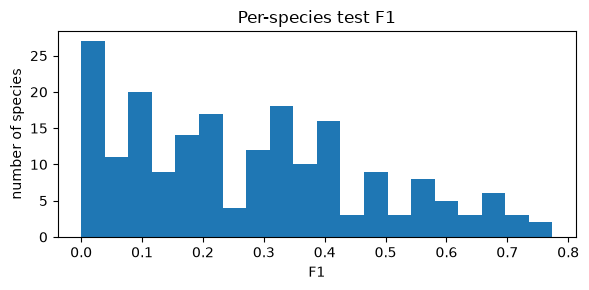

In [9]:
per_class = pd.Series(f1_score(y_test, y_pred, average=None, labels=model.classes_),
                      index=class_names.loc[model.classes_].values, name='F1')
print('Best classified species:');  print(per_class.nlargest(8).round(3).to_string())
print('\nWorst classified species:'); print(per_class.nsmallest(8).round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(per_class, bins=20, color='tab:blue')
ax.set(title='Per-species test F1', xlabel='F1', ylabel='number of species')
plt.tight_layout()
plt.show()

## 8. Interpretation

The main advantage of a decision tree is that it is transparent. Below we show the top of the tree, its first rules as text, and the attributes it relies on most.

- Only the **top 3 levels** are drawn. The full tree has dozens of levels and thousands of leaves, but the first splits are the most informative ones (they apply to the most images).
- **Caveat on feature importance:** the tree's built-in importance (mean decrease in impurity) is computed on training data and tends to favour features that are split on often. It shows what the tree *uses*, not necessarily what *generalises*. The Random Forest notebook adds permutation importance as a more reliable check.
- Importances are also **summed per attribute group** (e.g. all 15 `has_bill_color` columns). One-hot encoding spreads a body part's importance across many columns, so the group totals are easier to compare.

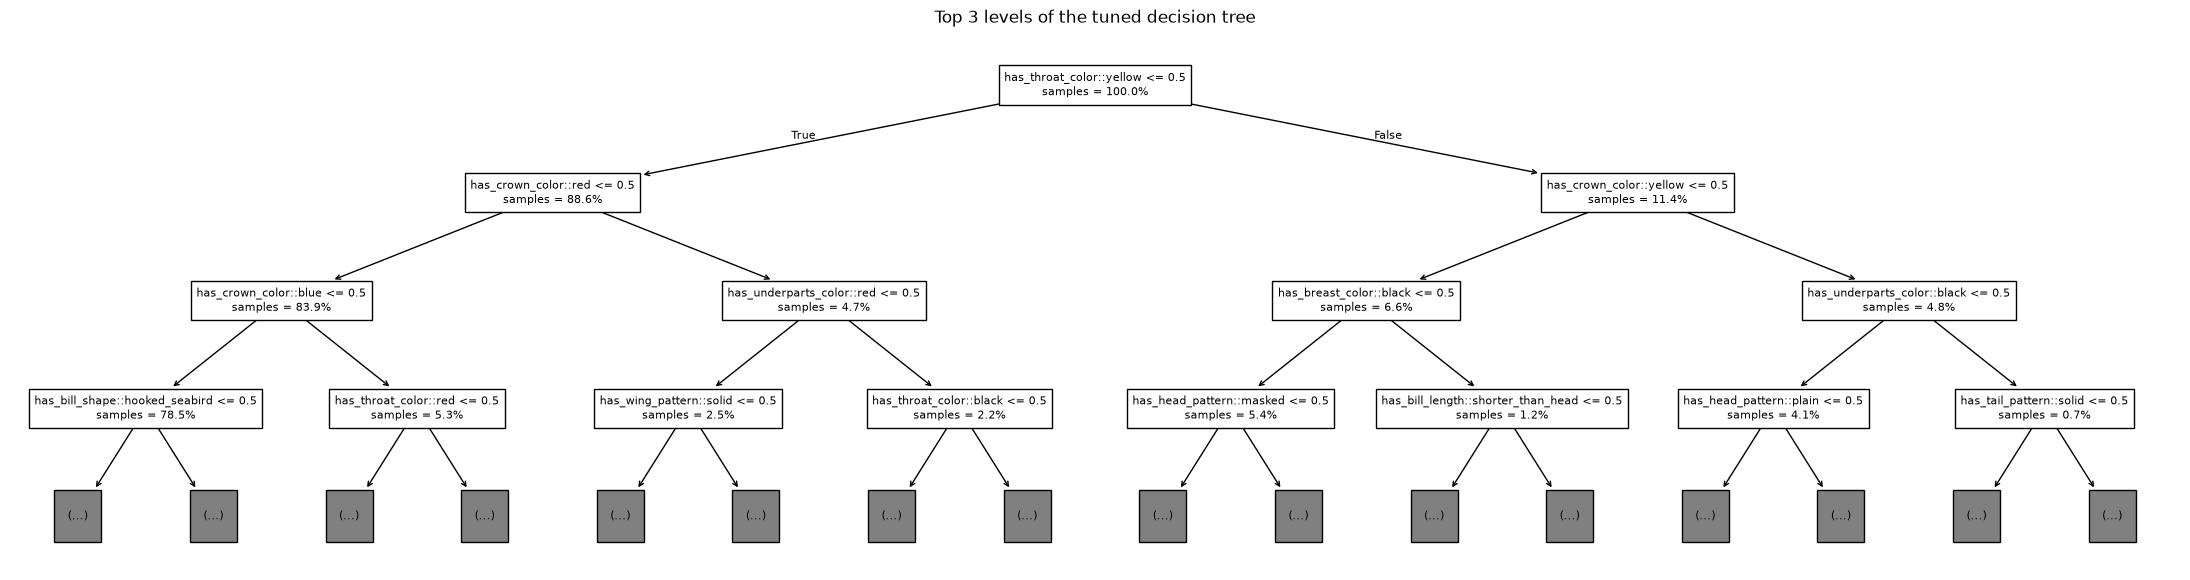

In [10]:
import re

fig, ax = plt.subplots(figsize=(28, 7))
nodes = plot_tree(model, max_depth=3, feature_names=list(X_train.columns),
                  impurity=False, proportion=True, fontsize=8, ax=ax)
# Each node would print a 200-class probability vector; keep only the split rule and sample share
for node in nodes:
    node.set_text(re.sub(r'\nvalue = \[.*?\]', '', node.get_text(), flags=re.S))
ax.set_title('Top 3 levels of the tuned decision tree')
plt.show()

In [11]:
print(export_text(model, feature_names=list(X_train.columns), max_depth=3, show_weights=False))

|--- has_throat_color::yellow <= 0.50
|   |--- has_crown_color::red <= 0.50
|   |   |--- has_crown_color::blue <= 0.50
|   |   |   |--- has_bill_shape::hooked_seabird <= 0.50
|   |   |   |   |--- truncated branch of depth 46
|   |   |   |--- has_bill_shape::hooked_seabird >  0.50
|   |   |   |   |--- truncated branch of depth 22
|   |   |--- has_crown_color::blue >  0.50
|   |   |   |--- has_throat_color::red <= 0.50
|   |   |   |   |--- truncated branch of depth 18
|   |   |   |--- has_throat_color::red >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |--- has_crown_color::red >  0.50
|   |   |--- has_underparts_color::red <= 0.50
|   |   |   |--- has_wing_pattern::solid <= 0.50
|   |   |   |   |--- truncated branch of depth 16
|   |   |   |--- has_wing_pattern::solid >  0.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- has_underparts_color::red >  0.50
|   |   |   |--- has_throat_color::black <= 0.50
|   |   |   |   |--- truncated branch of depth 10
|   |

features used by the tree: 265 / 312


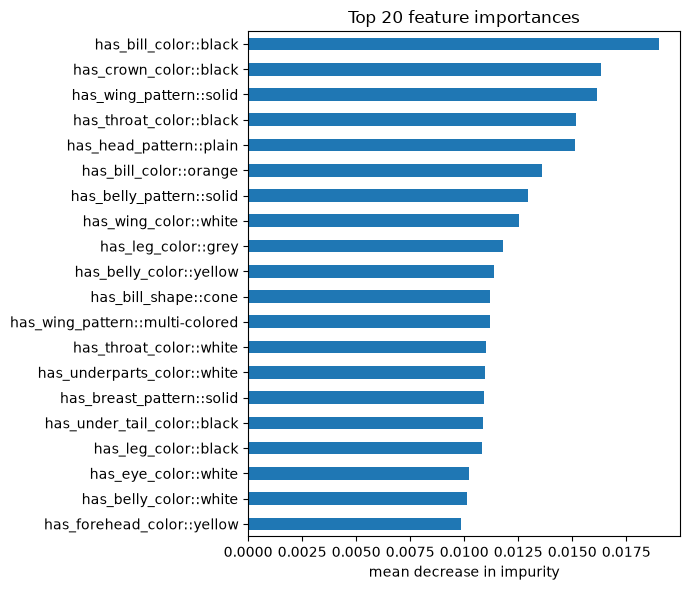

,importance (by attribute group)
has_crown_color,0.065
has_head_pattern,0.060
has_leg_color,0.060
has_throat_color,0.059
has_bill_color,0.057
has_belly_color,0.049
has_bill_shape,0.047
has_wing_color,0.045
has_forehead_color,0.043
has_underparts_color,0.041


In [12]:
importances = pd.Series(model.feature_importances_, index=X_train.columns)
print(f'features used by the tree: {(importances > 0).sum()} / {len(importances)}')

fig, ax = plt.subplots(figsize=(7, 6))
importances.nlargest(20).sort_values().plot.barh(ax=ax, color='tab:blue')
ax.set(title='Top 20 feature importances', xlabel='mean decrease in impurity')
plt.tight_layout()
plt.show()

group_imp = importances.groupby(importances.index.str.split('::').str[0]).sum().sort_values(ascending=False)
group_imp.head(10).round(3).to_frame('importance (by attribute group)')

## 9. Comparison with the official split

The 80/20 split changes two things at once: there are **more training images** (33–48 vs 29–30 per species) and the **test set is different** (and smaller). To separate the two effects:
1. **Official split:** the tuned tree from `decisionTree.ipynb` (the default unpruned tree on variant A) is refit here, to get its official-split numbers.
2. **80/20 test set, training capped at 30 images per species:** the selected configuration is retrained on a random 30 images per species from the 80/20 training portion (5 repeats with different subsamples). This keeps the 80/20 test set but uses the official split's training size.

If (2) matches the official result, the improvement on 80/20 comes from the extra training data. If (2) matches the full 80/20 result, the 80/20 test set is simply easier.

In [13]:
def official_split(name):
    df = pd.read_csv(DATA / f'cub_features_{name}.csv')
    features = [c for c in df.columns if c not in META_COLS]
    train, test = df[df.is_train == 1], df[df.is_train == 0]
    return train[features], train.class_id, test[features], test.class_id

Xo_train, yo_train, Xo_test, yo_test = official_split('A')
official_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xo_train, yo_train)
official_pred = official_tree.predict(Xo_test)
official_cv = cross_validate(DecisionTreeClassifier(random_state=RANDOM_STATE), Xo_train, yo_train,
                             cv=CV, scoring='accuracy')['test_score'].mean()

capped = []
for seed in range(5):
    sample = y_train.groupby(y_train).sample(n=30, random_state=seed).index
    capped_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, **best_gs.best_params_)
    capped_tree.fit(X_train.loc[sample], y_train.loc[sample])
    capped.append(accuracy_score(y_test, capped_tree.predict(X_test)))

split_comparison = pd.DataFrame({
    'official split': {'train images per species': '29-30', 'test images': len(yo_test),
                       'CV accuracy': official_cv, 'test accuracy': accuracy_score(yo_test, official_pred),
                       'test macro-F1': f1_score(yo_test, official_pred, average='macro')},
    '80/20, train capped at 30': {'train images per species': '30', 'test images': len(y_test),
                                  'CV accuracy': np.nan, 'test accuracy': np.mean(capped),
                                  'test macro-F1': np.nan},
    '80/20 split': {'train images per species': '33-48', 'test images': len(y_test),
                    'CV accuracy': results['cv_accuracy'], 'test accuracy': results['test_accuracy'],
                    'test macro-F1': results['test_f1_macro']},
}).T
print(f'capped-training test accuracy over 5 subsamples: {np.mean(capped):.3f} ± {np.std(capped):.3f}')
split_comparison

capped-training test accuracy over 5 subsamples: 0.255 ± 0.006


,train images per species,test images,CV accuracy,test accuracy,test macro-F1
official split,29-30,5794,0.246581,0.246807,0.245224
"80/20, train capped at 30",30,2358,NaN,0.254538,NaN
80/20 split,33-48,2358,0.271898,0.274385,0.273964


## 10. Summary

The cell below prints the headline numbers for the report.

**Findings (with `RANDOM_STATE = 42`, `SPLIT_SEED = 42`):**
- **Test accuracy is 27.4%** (macro-F1 0.274), against 24.7% on the official split: **+2.7 points**.
- **About two thirds of that gain comes from the extra training data** (§9). Training on just 30 images per species, but testing on the same 80/20 test set, gives 25.5% (±0.6). That's 0.8 points above the official split, a slightly easier or just different test set. The remaining 1.9 points come from the extra 3–18 training images per species. The single tree is data-limited, but only mildly.
- **Tuning still doesn't help.** The selected tree (variant B, `min_samples_leaf=2`, `min_samples_split=10`, `class_weight='balanced'`) scores 27.2% CV vs 26.8% for the default tree, a difference within the fold noise (±1 point). On the test set it is level with the default tree (27.4% vs 27.5%). As on the official split, restricting the tree doesn't improve generalisation.
- **The light restriction does change the tree's behaviour.** Training accuracy falls from 99.9% to 61%, and the tree has a third as many leaves (1,776 vs 5,223), at no cost in accuracy. Its leaves are no longer pure, so **top-5 accuracy becomes meaningful: 38.6%** (vs 26.4% on the official split, where the selected tree had pure leaves).
- **`class_weight='balanced'` makes no measurable difference.** It was chosen for variant B but not for A or C, and the scores with and without it are within noise. The 33–48 training imbalance is too mild to matter.
- **Feature variants are tied:** A 0.271, B 0.272, C 0.272 CV accuracy, all within about 0.1 points against a fold std of about 0.9. B was selected mechanically, but this confirms the official-split conclusion that encoding "not visible" brings no benefit.
- **Interpretation is unchanged.** The root split is still `has_throat_color::yellow`, followed by crown colour. Head and bill colour groups dominate the importances. Confused pairs are again lookalikes (gulls, cormorants, sparrows, crows), but with 8–12 test images per species these counts are small and noisy.
- **Recommendation:** the 80/20 split gives a modest, real gain from more training data, at the cost of a smaller, noisier test set. Whether to adopt it should be decided together with the Random Forest result, where more data is expected to matter more.

In [14]:
summary = pd.Series({'chance': 1 / y_train.nunique(), 'baseline test accuracy': baseline_test, **results})
summary

chance                       0.005
baseline test accuracy    0.275233
variant                          B
train_accuracy            0.610604
cv_accuracy               0.271898
test_accuracy             0.274385
test_f1_macro             0.273964
test_top5_accuracy        0.386344
depth                           49
leaves                        1776
dtype: object


## 11. Limitations

- **Single seed:** all results use `RANDOM_STATE = 42` and one fixed 80/20 split (`SPLIT_SEED = 42` in `dataPrep.ipynb`). A different split would give somewhat different numbers.
- **Smaller test set:** 2,358 test images (8–12 per species), against 5,794 on the official split. The test accuracy has a standard error of about ±0.9 points (vs about ±0.6), and the per-species F1 values in §7 rest on very few images each.
- **Not comparable with published results:** work on CUB-200-2011 normally reports the official split.
- **Label noise and identical vectors:** each image was annotated by one worker, and 16 groups of images have identical attributes but different species. Both put a ceiling on any tabular model.
- **Untested cleaning option:** the "drop guessing positives" switch in `dataPrep.ipynb` was not evaluated.
- **Training-data importances:** the feature importances in §8 come from the training data, so they describe the fitted tree rather than generalisation.
